# Lista de Exercícios — dados sintéticos e gráficos

Este caderno reproduz **todos os códigos, saídas e gráficos** da lista de exercícios (documento `Lista_de_Exercicios.docx`). Execute as células em ordem com `Shift + Enter`. Os valores são sempre os mesmos (sementes fixas). Depois de responder às questões, volte aqui para **testar variações**: mude K, o tamanho do teste, a semente, etc.

## Preparação (rode primeiro)

In [1]:
import numpy as np                                    # numpy: contas e sorteios aleatórios
import pandas as pd                                   # pandas: tabelas (DataFrame)
import matplotlib.pyplot as plt                       # matplotlib: gráficos
import seaborn as sns                                 # seaborn: estilo e heatmap
from sklearn.model_selection import train_test_split  # separa treino e teste
from sklearn.preprocessing import StandardScaler      # padroniza as variáveis
from sklearn.linear_model import LinearRegression     # regressão linear
from sklearn.neighbors import KNeighborsClassifier    # KNN
from sklearn.decomposition import PCA                 # PCA
from sklearn.cluster import KMeans                    # K-means
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, confusion_matrix, precision_score, recall_score)
import warnings
warnings.filterwarnings('ignore')                     # esconde avisos

sns.set_theme(style='whitegrid')                      # estilo dos gráficos
plt.rcParams['figure.figsize'] = (7, 4.5)             # tamanho padrão
AZUL, OURO, VERM, CINZA = '#16273E', '#F4AC02', '#C0392B', '#8C8C8C'   # cores

## Parte 1 — Regressão Linear Simples

**Situação:** uma professora registrou, para **60 alunos**, as horas de estudo por semana (`horas_estudo`) e a nota final (`nota`). Queremos **prever a nota a partir das horas de estudo**.

Os dados são sintéticos: a nota foi gerada como 30 + 5,5 × horas + um erro aleatório. Use o código, as saídas e os gráficos abaixo para responder às questões. O modelo foi treinado com 70% dos alunos e avaliado nos 30% restantes (**18 alunos de teste**).

In [2]:
rng = np.random.default_rng(7)                         # gerador aleatório com semente fixa
horas = rng.uniform(0, 10, 60).round(1)                # 60 alunos: horas de estudo por semana (0 a 10)
nota = (30 + 5.5 * horas + rng.normal(0, 8, 60)).round(1)   # nota = 30 + 5,5 x horas + erro aleatório (desvio 8)
df1 = pd.DataFrame({'horas_estudo': horas, 'nota': nota})   # junta tudo em uma tabela

print(df1.head())                                      # primeiras linhas
print('Correlação:', round(df1['horas_estudo'].corr(df1['nota']), 2))   # correlação de Pearson (r)

   horas_estudo  nota
0           6.3  59.2
1           9.0  81.1
2           7.8  69.2
3           2.3  43.7
4           3.0  37.0
Correlação: 0.93


In [3]:
X = df1[['horas_estudo']]                              # variável explicativa (colchetes duplos = tabela)
y = df1['nota']                                        # variável a prever
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42)   # 70% treino, 30% teste

modelo = LinearRegression()                            # cria o modelo
modelo.fit(X_treino, y_treino)                         # treina: encontra a melhor reta
y_prev = modelo.predict(X_teste)                       # prevê as notas do teste

print(f'Intercepto (b0): {modelo.intercept_:.2f}')     # nota prevista com 0 horas
print(f'Coeficiente (b1): {modelo.coef_[0]:.2f}')      # pontos de nota a mais por hora extra
print(f'R² no teste: {r2_score(y_teste, y_prev):.2f}')                       # fração da variação explicada
print(f'MAE no teste: {mean_absolute_error(y_teste, y_prev):.2f} pontos')    # erro médio absoluto
print(f'RMSE no teste: {np.sqrt(mean_squared_error(y_teste, y_prev)):.2f} pontos')   # raiz do erro quadrático médio

Intercepto (b0): 27.39
Coeficiente (b1): 5.90
R² no teste: 0.87
MAE no teste: 4.28 pontos
RMSE no teste: 5.45 pontos


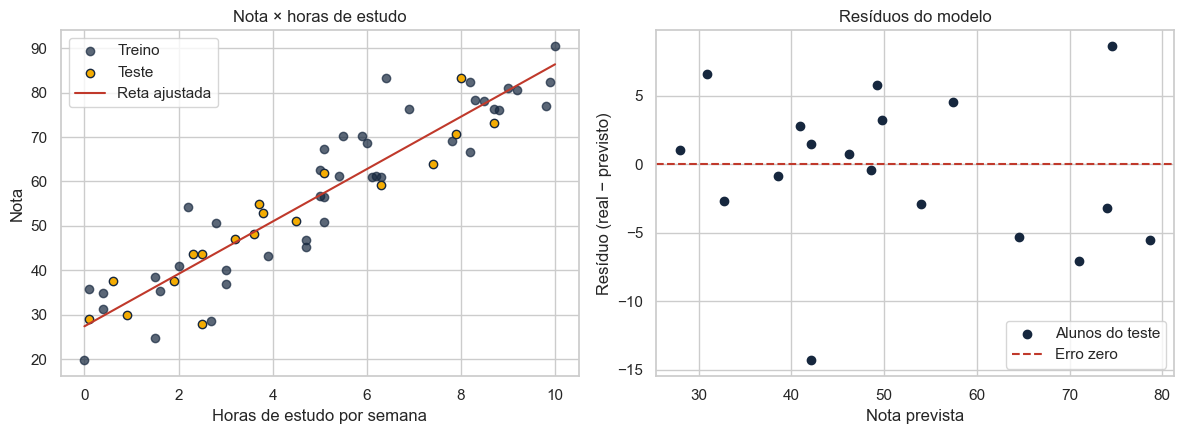

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))     # dois gráficos lado a lado

eixos[0].scatter(X_treino['horas_estudo'], y_treino, color=AZUL, alpha=0.7, label='Treino')   # pontos de treino
eixos[0].scatter(X_teste['horas_estudo'], y_teste, color=OURO, edgecolor=AZUL, label='Teste')  # pontos de teste
linha = np.array([[0], [10]])                          # dois valores de x para traçar a reta
eixos[0].plot(linha, modelo.predict(pd.DataFrame(linha, columns=['horas_estudo'])), color=VERM, label='Reta ajustada')   # reta
eixos[0].set_title('Nota × horas de estudo')           # título
eixos[0].set_xlabel('Horas de estudo por semana')      # eixo x
eixos[0].set_ylabel('Nota')                            # eixo y
eixos[0].legend()                                      # legenda

residuos = y_teste - y_prev                            # resíduo = valor real − valor previsto
eixos[1].scatter(y_prev, residuos, color=AZUL, label='Alunos do teste')   # resíduos × previsto
eixos[1].axhline(0, color=VERM, linestyle='--', label='Erro zero')        # linha de referência
eixos[1].set_title('Resíduos do modelo')               # título
eixos[1].set_xlabel('Nota prevista')                   # eixo x
eixos[1].set_ylabel('Resíduo (real − previsto)')       # eixo y
eixos[1].legend()                                      # legenda
plt.tight_layout()                                     # evita sobreposição
plt.show()                                             # exibe

## Parte 2 — Regressão Linear Múltipla

**Situação:** uma imobiliária registrou **200 apartamentos** com área (`area_m2`), número de quartos (`quartos`), distância ao metrô (`dist_metro_km`) e preço em milhares de reais (`preco_mil`). Queremos **prever o preço** com as três variáveis explicativas.

Os dados são sintéticos: os quartos crescem com a área (apartamentos maiores tendem a ter mais quartos) e o preço foi gerado como 60 + 5 × área + 10 × quartos − 25 × distância + erro. O teste tem **60 apartamentos**. O código ajusta também um modelo **simples** (só com a área) para comparação.

In [5]:
rng = np.random.default_rng(11)                        # semente fixa
n = 200                                                # 200 apartamentos
area = rng.uniform(35, 150, n).round(0)                # área em m²
quartos = np.clip(np.round(area / 40 + rng.normal(0, 0.5, n)), 1, 4)   # quartos crescem com a área (com ruído)
dist = rng.uniform(0.1, 5, n).round(1)                 # distância ao metrô em km
preco = (60 + 5 * area + 10 * quartos - 25 * dist + rng.normal(0, 40, n)).round(0)   # preço em mil R$ (fórmula + erro)

df2 = pd.DataFrame({'area_m2': area, 'quartos': quartos, 'dist_metro_km': dist, 'preco_mil': preco})   # tabela
print(df2.head())                                      # primeiras linhas
print(df2.corr().round(2))                             # matriz de correlação

   area_m2  quartos  dist_metro_km  preco_mil
0     50.0      1.0            2.0      165.0
1     92.0      3.0            1.9      518.0
2    104.0      2.0            4.6      577.0
3     38.0      1.0            2.0      186.0
4     52.0      2.0            4.0      273.0
               area_m2  quartos  dist_metro_km  preco_mil
area_m2           1.00     0.83          -0.07       0.96
quartos           0.83     1.00           0.04       0.79
dist_metro_km    -0.07     0.04           1.00      -0.24
preco_mil         0.96     0.79          -0.24       1.00


In [6]:
colunas = ['area_m2', 'quartos', 'dist_metro_km']      # variáveis explicativas
X = df2[colunas]                                       # X com 3 colunas
y = df2['preco_mil']                                   # alvo: preço
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42)   # divide treino/teste

modelo_m = LinearRegression().fit(X_treino, y_treino)  # regressão múltipla
y_prev_m = modelo_m.predict(X_teste)                   # previsões do teste

print(f'Intercepto: {modelo_m.intercept_:.1f}')        # b0
for nome, coef in zip(colunas, modelo_m.coef_):        # um coeficiente por variável
    print(f'Coeficiente de {nome}: {coef:.1f}')        # efeito, mantendo as outras fixas
print(f'R² múltipla (3 variáveis): {r2_score(y_teste, y_prev_m):.3f}')   # qualidade geral

modelo_s = LinearRegression().fit(X_treino[['area_m2']], y_treino)       # modelo simples: só a área
y_prev_s = modelo_s.predict(X_teste[['area_m2']])      # previsões do modelo simples
print(f'R² simples (só área):      {r2_score(y_teste, y_prev_s):.3f}')   # para comparar
print(f'MAE múltipla: {mean_absolute_error(y_teste, y_prev_m):.1f} mil R$')   # erro médio

Intercepto: 52.8
Coeficiente de area_m2: 5.0
Coeficiente de quartos: 11.9
Coeficiente de dist_metro_km: -24.2
R² múltipla (3 variáveis): 0.937
R² simples (só área):      0.899
MAE múltipla: 36.1 mil R$


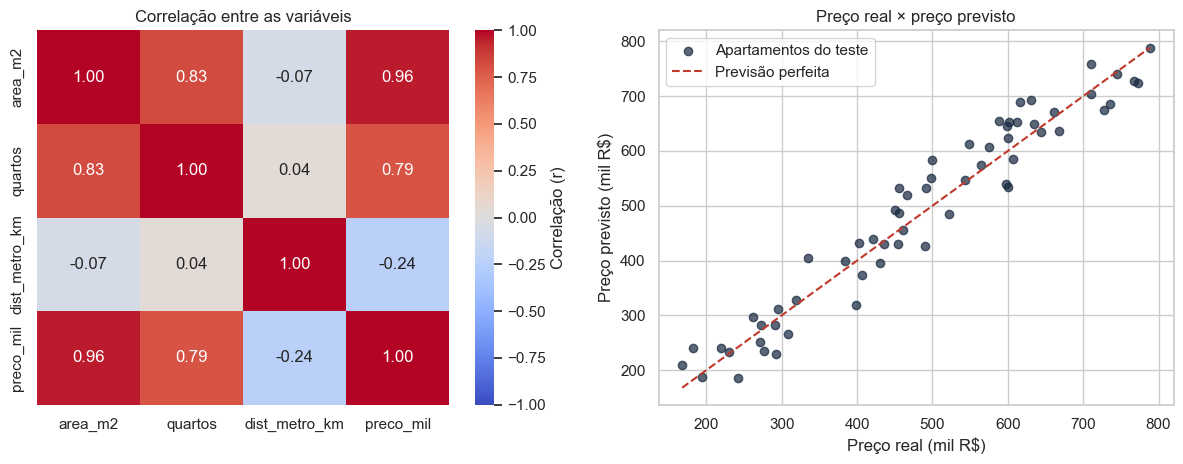

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8))     # dois gráficos

sns.heatmap(df2.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlação (r)'}, ax=eixos[0])   # mapa de calor das correlações
eixos[0].set_title('Correlação entre as variáveis')    # título

eixos[1].scatter(y_teste, y_prev_m, color=AZUL, alpha=0.7, label='Apartamentos do teste')   # real × previsto
lim = [y_teste.min(), y_teste.max()]                   # limites da linha de referência
eixos[1].plot(lim, lim, color=VERM, linestyle='--', label='Previsão perfeita')              # y = x
eixos[1].set_title('Preço real × preço previsto')      # título
eixos[1].set_xlabel('Preço real (mil R$)')             # eixo x
eixos[1].set_ylabel('Preço previsto (mil R$)')         # eixo y
eixos[1].legend()                                      # legenda
plt.tight_layout()                                     # evita sobreposição
plt.show()                                             # exibe

## Parte 3 — Classificação com KNN

**Situação:** uma loja online registrou **120 clientes** (60 que compraram e 60 que não compraram): renda mensal em reais (`renda_mensal`), visitas ao site por mês (`visitas_site`) e se o cliente comprou (`comprou`: 0 = não, 1 = sim). Queremos **classificar** se um cliente vai comprar.

Os dados são sintéticos: a renda é quase igual nos dois grupos (a diferença entre as médias é pequena perto do espalhamento), e a variável realmente informativa são as **visitas** (≈ 4 para quem não compra e ≈ 8 para quem compra). O teste tem **30 clientes** (15 de cada classe).

In [8]:
rng = np.random.default_rng(5)                         # semente fixa
n = 60                                                 # 60 clientes de cada classe
renda = np.concatenate([rng.normal(6000, 1800, n),     # não compra: renda média 6000
                        rng.normal(6500, 1800, n)]).round(-1)   # compra: renda média 6500 (quase igual)
visitas = np.concatenate([rng.normal(4, 2, n),         # não compra: ~4 visitas ao site por mês
                          rng.normal(8, 2, n)]).round(0)        # compra: ~8 visitas por mês
visitas = np.clip(visitas, 0, None)                    # não existe visita negativa
df3 = pd.DataFrame({'renda_mensal': renda, 'visitas_site': visitas,
                    'comprou': [0] * n + [1] * n})     # classe: 0 = não comprou, 1 = comprou

print(df3.groupby('comprou').mean().round(1))          # média de cada variável por classe
print(df3['comprou'].value_counts().to_string())       # quantos clientes de cada classe

         renda_mensal  visitas_site
comprou                            
0              5613.8           4.1
1              6229.0           8.3
comprou
0    60
1    60


In [9]:
X = df3[['renda_mensal', 'visitas_site']]              # variáveis explicativas
y = df3['comprou']                                     # classe a prever
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y) # 25% teste, mantendo a proporção das classes

knn_bruto = KNeighborsClassifier(n_neighbors=5).fit(X_treino, y_treino)   # KNN SEM padronizar
acc_bruto = knn_bruto.score(X_teste, y_teste)          # acurácia sem padronizar

scaler = StandardScaler()                              # padronizador
X_treino_pad = scaler.fit_transform(X_treino)          # aprende média e desvio no treino e padroniza
X_teste_pad = scaler.transform(X_teste)                # padroniza o teste com os valores do treino
knn = KNeighborsClassifier(n_neighbors=5).fit(X_treino_pad, y_treino)     # KNN COM padronização
y_prev = knn.predict(X_teste_pad)                      # previsões

print(f'Acurácia SEM padronizar: {acc_bruto:.2f}')     # resultado sem padronizar
print(f'Acurácia COM padronizar: {accuracy_score(y_teste, y_prev):.2f}')   # resultado padronizado

Acurácia SEM padronizar: 0.53
Acurácia COM padronizar: 0.77


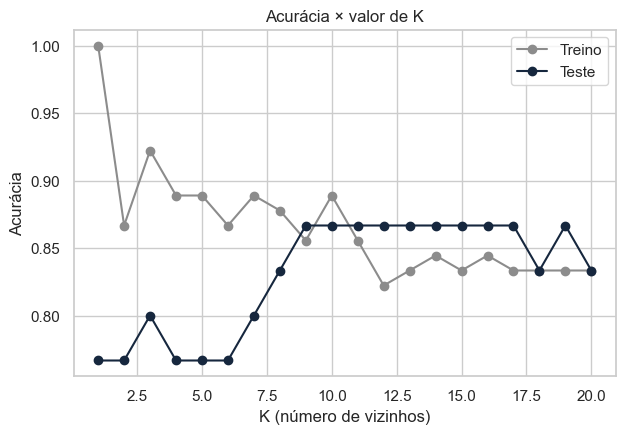

In [10]:
valores_k = range(1, 21)                               # K de 1 a 20
acc_treino, acc_teste = [], []                         # listas para guardar as acurácias
for k in valores_k:                                    # para cada K...
    m = KNeighborsClassifier(n_neighbors=k).fit(X_treino_pad, y_treino)   # treina
    acc_treino.append(m.score(X_treino_pad, y_treino)) # acurácia no treino
    acc_teste.append(m.score(X_teste_pad, y_teste))    # acurácia no teste

plt.plot(valores_k, acc_treino, color=CINZA, marker='o', label='Treino')   # curva do treino
plt.plot(valores_k, acc_teste, color=AZUL, marker='o', label='Teste')      # curva do teste
plt.title('Acurácia × valor de K')                     # título
plt.xlabel('K (número de vizinhos)')                   # eixo x
plt.ylabel('Acurácia')                                 # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

[[13  2]
 [ 2 13]]
Acurácia: 0.87
Precisão (comprou): 0.87
Recall (comprou):   0.87


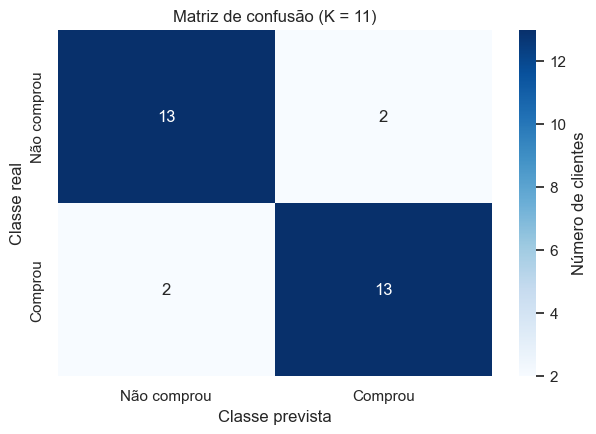

In [11]:
knn_final = KNeighborsClassifier(n_neighbors=11).fit(X_treino_pad, y_treino)   # modelo final com K = 11
y_prev = knn_final.predict(X_teste_pad)                # previsões do teste

print(confusion_matrix(y_teste, y_prev))               # linhas = real, colunas = previsto
print(f'Acurácia: {accuracy_score(y_teste, y_prev):.2f}')    # fração de acertos
print(f'Precisão (comprou): {precision_score(y_teste, y_prev):.2f}')   # dos que previ "compra", quantos compraram
print(f'Recall (comprou):   {recall_score(y_teste, y_prev):.2f}')      # dos que compraram, quantos encontrei

sns.heatmap(confusion_matrix(y_teste, y_prev), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não comprou', 'Comprou'], yticklabels=['Não comprou', 'Comprou'],
            cbar_kws={'label': 'Número de clientes'})  # matriz de confusão desenhada
plt.title('Matriz de confusão (K = 11)')               # título
plt.xlabel('Classe prevista')                          # eixo x
plt.ylabel('Classe real')                              # eixo y
plt.show()                                             # exibe

## Parte 4 — PCA e K-means

**Situação:** um aplicativo de compras registrou **300 clientes** com quatro variáveis: gasto mensal em reais (`gasto_mensal`), número de compras no mês (`compras_mes`), ticket médio em reais (`ticket_medio`) e tempo no aplicativo em minutos (`tempo_app_min`). Não há classes conhecidas: queremos **resumir as variáveis com PCA** e **descobrir grupos de clientes com K-means**.

Os dados são sintéticos e foram gerados a partir de 3 perfis (econômico, regular e premium). O nome do perfil real (`perfil_real`) **não** é entregue aos algoritmos: serve apenas para conferir o resultado no final.

In [12]:
rng = np.random.default_rng(4)                         # semente fixa
n = 100                                                # 100 clientes de cada perfil
medias = {'Econômico': (200, 4, 50, 15),               # (gasto, compras, ticket, tempo no app)
          'Regular': (500, 8, 62, 30),
          'Premium': (1200, 9, 130, 25)}
desvios = (90, 1.5, 12, 6)                             # espalhamento de cada variável
linhas, perfil_real = [], []                           # listas para montar a tabela
for nome, m in medias.items():                         # para cada perfil...
    linhas.append(np.column_stack([rng.normal(m[i], desvios[i], n) for i in range(4)]))   # sorteia as 4 variáveis
    perfil_real += [nome] * n                          # guarda o perfil verdadeiro (só para conferir depois)
df4 = pd.DataFrame(np.vstack(linhas), columns=['gasto_mensal', 'compras_mes', 'ticket_medio', 'tempo_app_min']).round(0)

print(df4.describe().loc[['mean', 'std']].round(1))    # média e desvio de cada variável
print(df4.corr().round(2))                             # correlações entre as variáveis

      gasto_mensal  compras_mes  ticket_medio  tempo_app_min
mean         624.4          7.1          81.3           22.9
std          427.3          2.6          36.7            9.2
               gasto_mensal  compras_mes  ticket_medio  tempo_app_min
gasto_mensal           1.00         0.67          0.91           0.35
compras_mes            0.67         1.00          0.52           0.51
ticket_medio           0.91         0.52          1.00           0.22
tempo_app_min          0.35         0.51          0.22           1.00


In [13]:
pca_bruto = PCA().fit(df4)                             # PCA SEM padronizar
print('Variância explicada SEM padronizar:', pca_bruto.explained_variance_ratio_.round(3))   # fração de cada PC

X_pad = StandardScaler().fit_transform(df4)            # padroniza as 4 variáveis
pca = PCA().fit(X_pad)                                 # PCA COM padronização (4 componentes)
var = pca.explained_variance_ratio_                    # fração de cada componente
print('Variância explicada COM padronizar:', var.round(3))
print('Acumulada:', var.cumsum().round(3))             # soma acumulada

pesos = pd.DataFrame(pca.components_[:2], columns=df4.columns, index=['PC1', 'PC2'])   # pesos das variáveis em PC1 e PC2
print(pesos.round(2))                                  # tabela de pesos

Variância explicada SEM padronizar: [0.998 0.001 0.    0.   ]
Variância explicada COM padronizar: [0.661 0.226 0.096 0.018]
Acumulada: [0.661 0.886 0.982 1.   ]
     gasto_mensal  compras_mes  ticket_medio  tempo_app_min
PC1          0.58         0.51          0.53           0.35
PC2         -0.29         0.24         -0.46           0.80


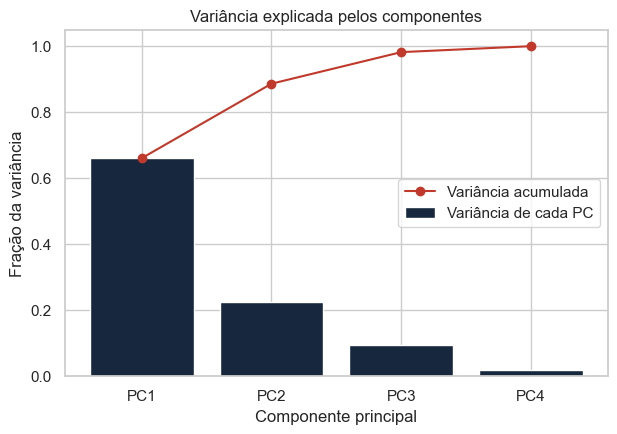

In [14]:
nomes_pc = ['PC1', 'PC2', 'PC3', 'PC4']                # nomes dos componentes
plt.bar(nomes_pc, var, color=AZUL, label='Variância de cada PC')   # barras
plt.plot(nomes_pc, var.cumsum(), color=VERM, marker='o', label='Variância acumulada')   # linha acumulada
plt.title('Variância explicada pelos componentes')     # título
plt.xlabel('Componente principal')                     # eixo x
plt.ylabel('Fração da variância')                      # eixo y
plt.legend(loc='center right')                         # legenda
plt.show()                                             # exibe

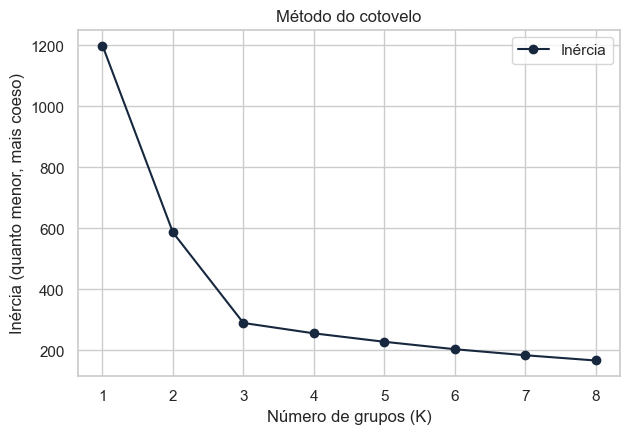

Inércias: [1200, 587, 290, 256, 228, 204, 184, 167]


In [15]:
inercias = []                                          # lista para guardar a inércia de cada K
for k in range(1, 9):                                  # K de 1 a 8
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pad)   # K-means com esse K
    inercias.append(km.inertia_)                       # guarda a inércia

plt.plot(range(1, 9), inercias, color=AZUL, marker='o', label='Inércia')   # curva do cotovelo
plt.title('Método do cotovelo')                        # título
plt.xlabel('Número de grupos (K)')                     # eixo x
plt.ylabel('Inércia (quanto menor, mais coeso)')       # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe
print('Inércias:', [round(i) for i in inercias])       # valores numéricos

In [16]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)  # K-means com K = 3
df4['grupo'] = km.fit_predict(X_pad)                   # grupo (0, 1 ou 2) de cada cliente

print(df4.groupby('grupo').mean().round(1))            # perfil médio de cada grupo
print(df4['grupo'].value_counts().sort_index().to_string())   # tamanho de cada grupo
print(pd.crosstab(pd.Series(perfil_real, name='Perfil real'), df4['grupo']))   # conferência com o perfil verdadeiro

       gasto_mensal  compras_mes  ticket_medio  tempo_app_min
grupo                                                        
0             490.5          8.2          61.0           30.5
1            1189.5          9.0         129.8           25.0
2             204.6          4.3          53.4           14.0
grupo
0     96
1    100
2    104
grupo         0    1    2
Perfil real              
Econômico     0    0  100
Premium       0  100    0
Regular      96    0    4


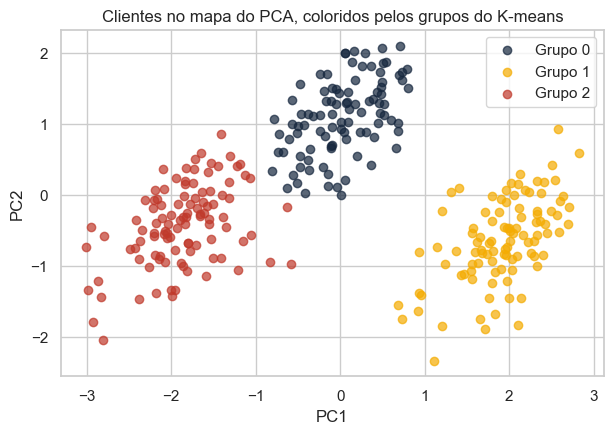

In [17]:
pcs = PCA(n_components=2).fit_transform(X_pad)         # resume os clientes em 2 componentes
for g, cor in zip([0, 1, 2], [AZUL, OURO, VERM]):      # um grupo por vez
    plt.scatter(pcs[df4['grupo'] == g, 0], pcs[df4['grupo'] == g, 1], color=cor, alpha=0.7, label=f'Grupo {g}')
plt.title('Clientes no mapa do PCA, coloridos pelos grupos do K-means')   # título
plt.xlabel('PC1')                                      # eixo x
plt.ylabel('PC2')                                      # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe